# Lepton-jet reconstruction efficiency, step 2: data against simulation in the control samples

The data part of step 2 of [`lj_reco_efficiency.md`](lj_reco_efficiency.md): the passing fraction
of the probes of the two control samples in data, against the simulation of
[`07_lj_reco_control_samples.ipynb`](07_lj_reco_control_samples.ipynb).

**Data.** Campaign `lj_reco_cr_data_v1`: all 2018 DoubleMuon files, the `_alone` versions of the
two control samples only, so no event of the signal region enters. The advisor approved reading
data in these control samples, each thought through before its first look. The data are read only
through `systematics_study.lj_cr_data`, which takes the safety table that notebook 07 wrote to EOS
and stops unless every region it reads is safe; notebook 07 found every region of both samples safe.

**The comparison.** For each control sample, the passing fraction after the sideband subtraction
(`systematics_study.probe_efficiency`), in data and in the simulated background:

* $J/\psi \to \mu\mu$ (muon-type lepton jets): against the pair $p_T$, the opening angle
  $\Delta R(\mu\mu)$ and $|\eta|$;
* $Z \to \mu\mu\gamma$ (egamma-type lepton jets): for unconverted photons ($R_9 \geq 0.94$) above
  30 GeV, where notebook 07 showed that the subtraction gives the same efficiency whatever the
  background, against the photon $p_T$ and $|\eta|$.

The simulation keeps the provisional lepton scale factors, so the data/simulation ratios measure
what they miss.

In [1]:
import os, shutil, sys, tempfile, json, warnings
from pathlib import Path
import numpy as np
import hist
import matplotlib.pyplot as plt

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # on the path through systematics_study  # pylint: disable=import-error

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)

DATA_DIR = sysstudy.eos_url(sysstudy.LJ_CR_DATA_DIR)              # merged outputs of lj_reco_cr_data_v1
SIM_DIR = sysstudy.eos_url(sysstudy.LJ_CR_DIR)                    # merged outputs of lj_reco_cr_v2
OUTPUT_DIR = sysstudy.eos_url(sysstudy.LJ_CR_DATA_RESULTS_DIR)    # figures and passing fractions
if not sysstudy.list_coffea(DATA_DIR):
    raise FileNotFoundError(f"No merged outputs in {DATA_DIR} yet: run the campaign lj_reco_cr_data_v1 "
                            "(condor/README.md, section 23)")
WORK = Path(tempfile.mkdtemp(prefix="lj_reco_cr_data_v1_"))   # removed at the end
# the Z -> mumu gamma probes compared: unconverted photons above 30 GeV
Z_SELECTION = {"probe_pt": slice(hist.loc(30), None, sum), "probe_r9": slice(hist.loc(0.94), None, sum)}


def save(fig, name):
    """Write a figure into the working directory, for EOS, as PDF and PNG"""
    for suffix in (".pdf", ".png"):
        fig.savefig(WORK / f"{name}{suffix}", bbox_inches="tight")


print("data:      ", DATA_DIR)
print("simulation:", SIM_DIR)
print("outputs:   ", OUTPUT_DIR)

data:       root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_data_v1
simulation: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_v2
outputs:    root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_data_v1_results


## 1. Inputs, through the safety table

The safety table of notebook 07 is read back first (`lj_cr_verdicts`, which also checks that it was
judged with the current sparse-bin rule); `lj_cr_data` then reads the data, refusing any region the
table does not mark safe and setting such regions to zero before anything else is done with them.
Below, per control sample, the probes in the peak and after the sideband subtraction, in data and
in the simulation.

In [2]:
rows = sysstudy.lj_cr_verdicts(sysstudy.LJ_CR_RESULTS_DIR)
for cr in sysstudy.LJ_CR:
    print(f"{cr}: readable regions: {len(sysstudy.lj_cr_readable(rows, cr))}")
data = sysstudy.lj_cr_data(rows, DATA_DIR)
sim = sysstudy.lj_cr_inputs(SIM_DIR)
sim_total = {cr: sum(per[cr] for per in sim["background"].values()) for cr in sysstudy.LJ_CR}
print()
for cr, spec in sysstudy.LJ_CR.items():
    (lo, hi), sidebands = spec["peak"], spec["sidebands"]
    k = (hi - lo) / sum(b - a for a, b in sidebands)
    for label, h in (("data", data[cr]), ("simulation", sim_total[cr])):
        peak = sysstudy.mass_window(h, spec["mass"], lo, hi).sum(flow=True).value
        side = sum(sysstudy.mass_window(h, spec["mass"], a, b).sum(flow=True).value for a, b in sidebands)
        print(f"{cr:16s} {label:10s}: {peak:10.4g} probes in the peak, {peak - k * side:10.4g} after the subtraction")

Z -> mumu gamma: readable regions: 10
J/psi -> mumu: readable regions: 10



Z -> mumu gamma  data      :  2.033e+04 probes in the peak,  1.062e+04 after the subtraction
Z -> mumu gamma  simulation:   1.84e+04 probes in the peak,       9966 after the subtraction
J/psi -> mumu    data      :   4.05e+05 probes in the peak,  3.271e+05 after the subtraction
J/psi -> mumu    simulation:  4.803e+05 probes in the peak,  3.818e+05 after the subtraction


**Interpretation (run of 2026-11-17: `lj_reco_cr_data_v1`, all 68 data samples; simulation
`lj_reco_cr_v2`).** All ten regions of each sample are readable, so the data are read in full.
After the sideband subtraction the data hold 10,620 $Z \to \mu\mu\gamma$ probes against 9,966 in
the simulation (a ratio of 1.07), and 327,000 $J/\psi$ probes against 382,000 (0.86): the
simulation describes both yields within 15%, which the passing fractions do not depend on.

## 2. The probe mass in data and simulation

The simulation at its luminosity, stacked by process; the data as points. For the $Z$, the
probes compared in section 4 (unconverted photons above 30 GeV), passing and failing.

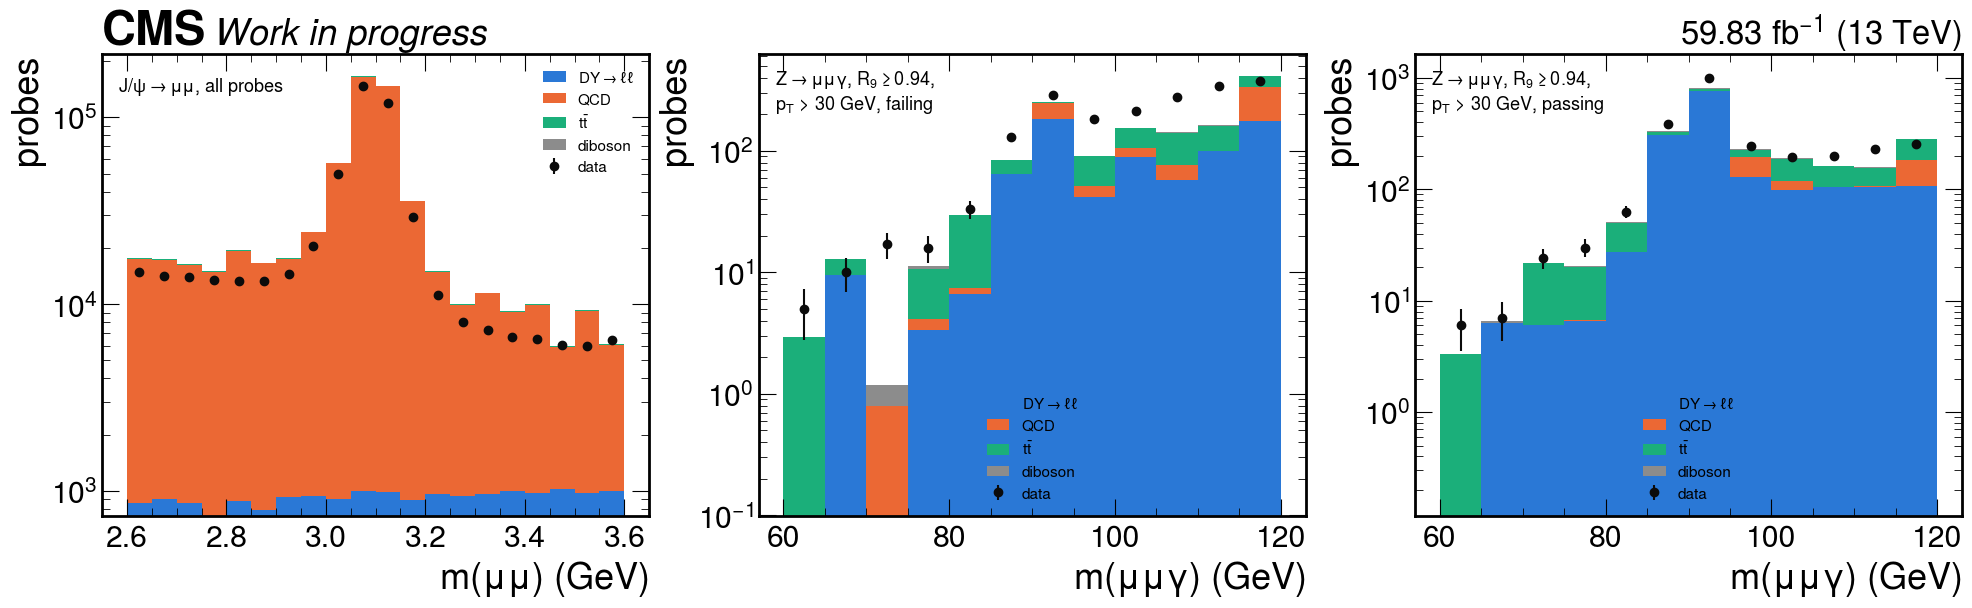

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
sysstudy.plot_mass_data_mc(data, sim, "J/psi -> mumu", ax=axes[0])
axes[0].text(0.03, 0.92, sysstudy.LJ_CR["J/psi -> mumu"]["label"] + ", all probes", transform=axes[0].transAxes, fontsize=13)
for ax, passing, title in ((axes[1], 0, "failing"), (axes[2], 1, "passing")):
    sysstudy.plot_mass_data_mc(data, sim, "Z -> mumu gamma", sel={**Z_SELECTION, "passing": passing}, ax=ax)
    ax.text(0.03, 0.88, sysstudy.LJ_CR["Z -> mumu gamma"]["label"] + rf", $R_9 \geq 0.94$," + "\n" + rf"$p_T$ > 30 GeV, {title}",
            transform=ax.transAxes, fontsize=13)
for ax in axes:
    ax.set_yscale("log")
pt.cms_label(axes, data=True, text="Work in progress")
save(fig, "mass_data_simulation")
plt.show()

**Interpretation.** The $J/\psi$ peak has the same shape in data and simulation, with the
simulation about 15% higher in the peak and the sidebands alike. Among the unconverted photons
above 30 GeV, the passing probes peak at the Z mass in data as in the simulation; the failing
probes hold more events in data than in the simulation above the peak, photons that do not come
from the Z, which the adjacent sidebands remove.

## 3. Muon-type lepton jets: $J/\psi \to \mu\mu$

The passing fraction in data and in the simulated background against the pair $p_T$, the opening
angle and $|\eta|$, and their ratio.

J/psi -> mumu against probe_pt:  low-high: data | simulation | data/simulation
   20-30: 0.379 +- 0.033 | 1.318 +- 1.579 | 0.288 +- 0.346
   30-40: 0.691 +- 0.009 | 0.746 +- 0.106 | 0.926 +- 0.133
   40-50: 0.818 +- 0.006 | 0.936 +- 0.043 | 0.874 +- 0.040
   50-60: 0.964 +- 0.001 | 0.962 +- 0.015 | 1.002 +- 0.016
   60-80: 0.985 +- 0.001 | 1.003 +- 0.012 | 0.982 +- 0.012
   80-100: 0.986 +- 0.001 | 0.996 +- 0.004 | 0.989 +- 0.004
   100-150: 0.987 +- 0.001 | 0.990 +- 0.004 | 0.997 +- 0.004
   150-300: 0.987 +- 0.006 | 1.015 +- 0.059 | 0.973 +- 0.057
J/psi -> mumu against probe_dR:  low-high: data | simulation | data/simulation
   0-0.01: nan +- nan | nan +- nan | nan +- nan
   0.01-0.02: 0.773 +- 0.139 | 0.321 +- 0.245 | 2.405 +- 1.886
   0.02-0.03: 0.926 +- 0.031 | 0.871 +- 0.057 | 1.063 +- 0.078
   0.03-0.05: 0.988 +- 0.004 | 1.008 +- 0.032 | 0.980 +- 0.031
   0.05-0.08: 0.989 +- 0.001 | 0.996 +- 0.002 | 0.993 +- 0.002
   0.08-0.12: 0.986 +- 0.000 | 0.991 +- 0.003 | 0.994 +- 0.003
  

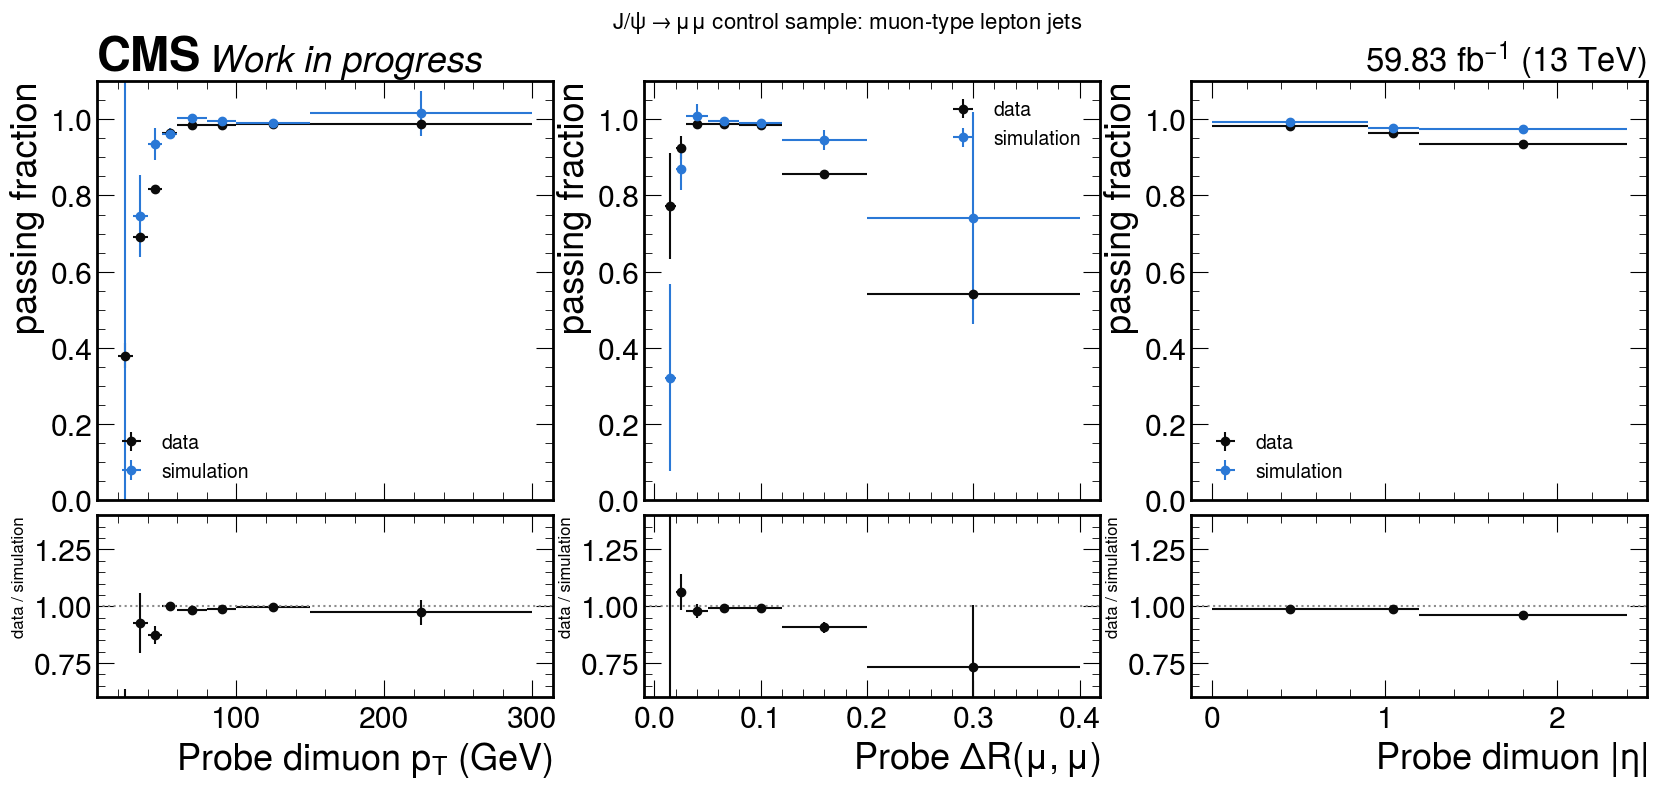

In [4]:
spec = spec_j = sysstudy.LJ_CR["J/psi -> mumu"]
tables = {}
fig, axes = plt.subplots(2, 3, figsize=(20, 8), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05})
for col, axis in enumerate(("probe_pt", "probe_dR", "probe_abseta")):
    results = {"data": sysstudy.probe_efficiency(data["J/psi -> mumu"], spec, axis),
               "simulation": sysstudy.probe_efficiency(sim_total["J/psi -> mumu"], spec, axis)}
    sysstudy.plot_efficiency_comparison(results, "simulation", axes[0, col], axes[1, col])
    tables[("J/psi -> mumu", axis)] = sysstudy.efficiency_table(results, "simulation")
    print(f"J/psi -> mumu against {axis}:  low-high: data | simulation | data/simulation")
    for lo, hi, d, de, s, se, r, re in tables[("J/psi -> mumu", axis)]:
        print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
fig.suptitle(f"{spec['label']} control sample: {spec['lj_type']} lepton jets", fontsize=16, y=0.97)
pt.cms_label(axes[0], data=True, text="Work in progress")
save(fig, "efficiency_jpsi_data_simulation")
plt.show()

**Interpretation.** Above 50 GeV the passing fraction is 0.96 to 0.99 in data and agrees
with the simulation within 1 to 2% in every bin: data/simulation 1.002 ± 0.016, 0.982 ± 0.012,
0.989 ± 0.004, 0.997 ± 0.004 and 0.97 ± 0.06 from 50 to 300 GeV. Near the 30 GeV threshold of the
lepton jets the data turn on more slowly (0.87 ± 0.04 from 40 to 50 GeV). Inside a wide bin near a
threshold the passing fraction depends on the $p_T$ spectrum within the bin, which differs between
the prompt and non-prompt $J/\psi$ of the data and the non-prompt ones of the simulation, so this
region does not give a scale factor. The large opening angles ($\Delta R \geq 0.12$) are the
low-$p_T$ pairs ($\Delta R \approx 2m/p_T$) and show the same threshold.

Away from the 30 GeV threshold of the lepton jets, whose turn-on depends on the $p_T$ spectrum
inside each bin (which differs between the prompt and non-prompt $J/\psi$ of the data and the
non-prompt ones of the simulation): the $p_T$ dependence from the threshold on, then the passing
fraction against the opening angle and $|\eta|$ for pairs above 50 GeV, and for all of them
together.

J/psi -> mumu, pT > 50 GeV, against probe_dR:  data | simulation | data/simulation
   0-0.01: nan +- nan | nan +- nan | nan +- nan
   0.01-0.02: 0.773 +- 0.139 | 0.321 +- 0.245 | 2.405 +- 1.886
   0.02-0.03: 0.926 +- 0.031 | 0.871 +- 0.057 | 1.063 +- 0.078
   0.03-0.05: 0.988 +- 0.004 | 1.008 +- 0.032 | 0.980 +- 0.031
   0.05-0.08: 0.989 +- 0.001 | 0.996 +- 0.002 | 0.993 +- 0.002
   0.08-0.12: 0.985 +- 0.000 | 0.991 +- 0.003 | 0.994 +- 0.003
   0.12-0.2: 0.832 +- 0.008 | 0.885 +- 0.056 | 0.940 +- 0.060
   0.2-0.4: 0.034 +- 0.060 | nan +- nan | nan +- nan
J/psi -> mumu, pT > 50 GeV, against probe_abseta:  data | simulation | data/simulation
   0-0.9: 0.991 +- 0.000 | 1.000 +- 0.009 | 0.991 +- 0.009
   0.9-1.2: 0.979 +- 0.001 | 0.985 +- 0.007 | 0.994 +- 0.007
   1.2-2.4: 0.959 +- 0.001 | 0.983 +- 0.008 | 0.976 +- 0.008
all probes above 50 GeV: data 0.9819 +- 0.0004, simulation 0.9936 +- 0.0062, data/simulation 0.988 +- 0.006


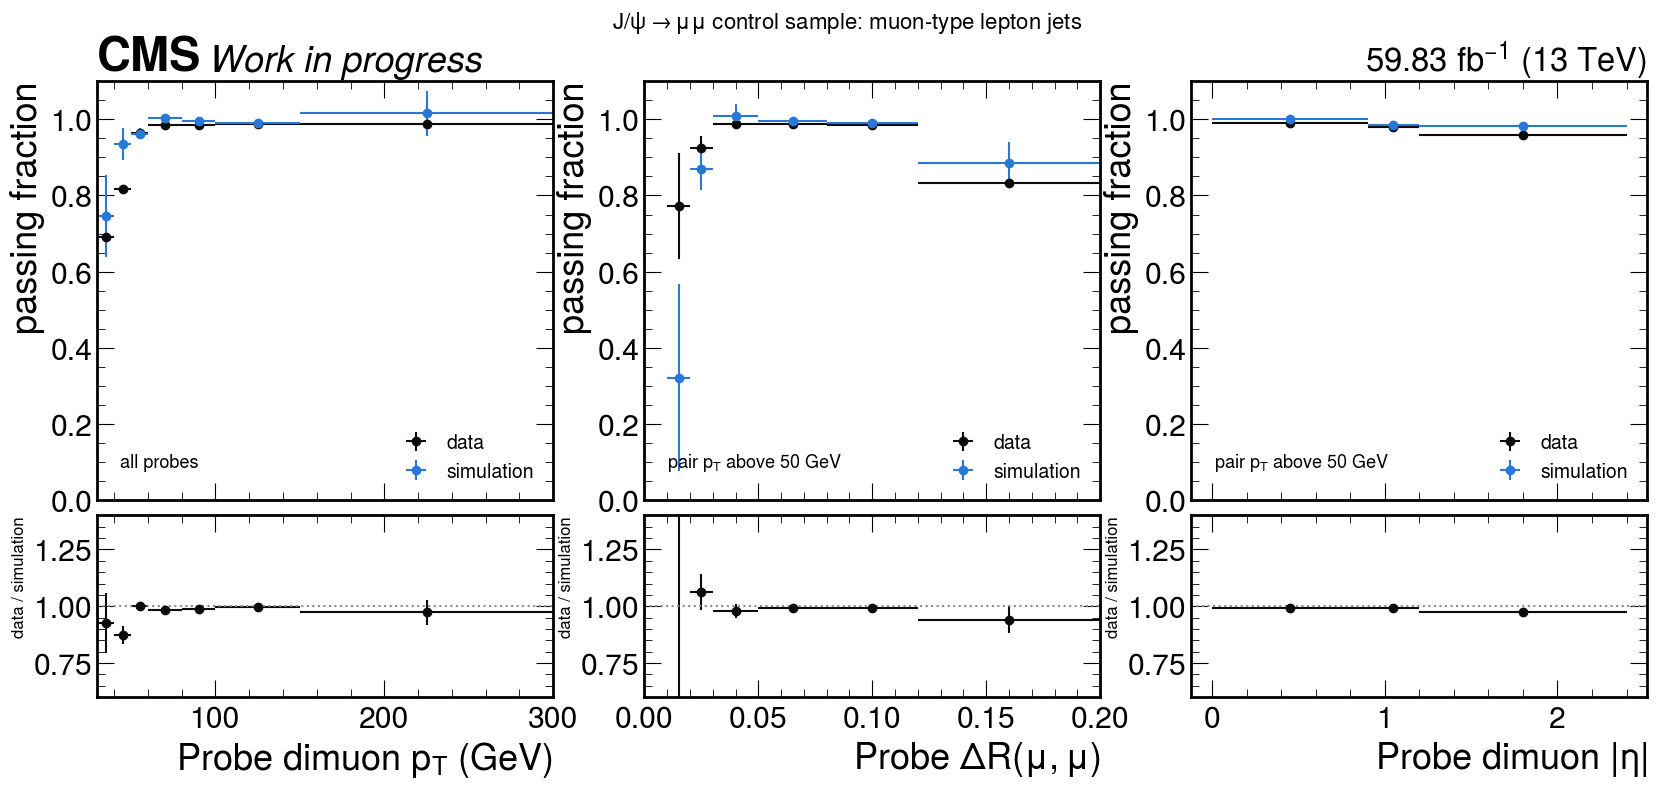

In [5]:
above = {"probe_pt": slice(hist.loc(50), None, sum)}
fig, axes = plt.subplots(2, 3, figsize=(20, 8), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05})
# the pT dependence from the lepton-jet threshold on, then the other axes above 50 GeV
results = {"data": sysstudy.probe_efficiency(data["J/psi -> mumu"], spec_j, "probe_pt"),
           "simulation": sysstudy.probe_efficiency(sim_total["J/psi -> mumu"], spec_j, "probe_pt")}
sysstudy.plot_efficiency_comparison(results, "simulation", axes[0, 0], axes[1, 0])
axes[1, 0].set_xlim(30, 300)
axes[0, 0].text(0.05, 0.08, "all probes", transform=axes[0, 0].transAxes, fontsize=13)
for col, axis in ((1, "probe_dR"), (2, "probe_abseta")):
    results = {"data": sysstudy.probe_efficiency(data["J/psi -> mumu"][above], spec_j, axis),
               "simulation": sysstudy.probe_efficiency(sim_total["J/psi -> mumu"][above], spec_j, axis)}
    sysstudy.plot_efficiency_comparison(results, "simulation", axes[0, col], axes[1, col])
    axes[0, col].text(0.05, 0.08, r"pair $p_T$ above 50 GeV", transform=axes[0, col].transAxes, fontsize=13)
    tables[("J/psi -> mumu, pT > 50 GeV", axis)] = sysstudy.efficiency_table(results, "simulation")
    print(f"J/psi -> mumu, pT > 50 GeV, against {axis}:  data | simulation | data/simulation")
    for lo, hi, d, de, s, se, r, re in tables[("J/psi -> mumu, pT > 50 GeV", axis)]:
        print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
axes[1, 1].set_xlim(0, 0.2)   # above 50 GeV a J/psi pair has dR = 2m/pT < 0.13
values = {label: sysstudy.integrated_efficiency(h[above], spec_j) for label, h in
          (("data", data["J/psi -> mumu"]), ("simulation", sim_total["J/psi -> mumu"]))}
(d, de, _), (s, se, _) = values["data"], values["simulation"]
print(f"all probes above 50 GeV: data {d:.4f} +- {de:.4f}, simulation {s:.4f} +- {se:.4f}, "
      f"data/simulation {d / s:.3f} +- {d / s * np.hypot(de / d, se / s):.3f}")
fig.suptitle(f"{spec_j['label']} control sample: {spec_j['lj_type']} lepton jets", fontsize=16, y=0.97)
pt.cms_label(axes[0], data=True, text="Work in progress")
save(fig, "efficiency_jpsi_above50_data_simulation")
plt.show()

**Interpretation.** Above 50 GeV, all probes together: data 0.9819 ± 0.0004, simulation
0.9936 ± 0.0062, a ratio of **0.988 ± 0.006**, limited by the statistics of the simulation. Against
$|\eta|$: 0.991 ± 0.009 in the barrel, 0.994 ± 0.007 in the overlap and 0.976 ± 0.008 in the
endcaps. Against the opening angle: 0.993 ± 0.002 and 0.994 ± 0.003 from 0.05 to 0.12, 0.98 ±
0.03 from 0.03 to 0.05, 1.06 ± 0.08 from 0.02 to 0.03; below 0.02 both samples hold few probes
(data 0.77 ± 0.14, simulation 0.32 ± 0.25).

## 4. Egamma-type lepton jets: $Z \to \mu\mu\gamma$

Unconverted photons ($R_9 \geq 0.94$) above 30 GeV: the passing fraction in data, in the simulated
background and in Drell-Yan alone, against the photon $p_T$ and $|\eta|$, and the ratio of the data
to the simulated background.

Z -> mumu gamma (R9 >= 0.94) against probe_pt:  data | simulation | data/simulation
   20-25: 0.001 +- 0.001 | 0.003 +- 0.002 | 0.263 +- 0.382
   25-30: 0.005 +- 0.003 | 0.003 +- 0.003 | 1.750 +- 2.024
   30-35: 0.877 +- 0.022 | 0.841 +- 0.045 | 1.043 +- 0.062
   35-40: 0.823 +- 0.034 | 0.987 +- 0.078 | 0.834 +- 0.075
   40-50: 0.879 +- 0.042 | 0.614 +- 0.153 | 1.432 +- 0.363
   50-60: 0.856 +- 0.059 | 0.889 +- 0.090 | 0.963 +- 0.118
   60-80: 0.752 +- 0.055 | 0.946 +- 0.075 | 0.795 +- 0.086
   80-120: 0.735 +- 0.081 | 1.192 +- 0.184 | 0.617 +- 0.117
Z -> mumu gamma (R9 >= 0.94, pT > 30 GeV) against probe_abseta:  data | simulation | data/simulation
   0-0.8: 0.877 +- 0.021 | 0.786 +- 0.079 | 1.117 +- 0.116
   0.8-1.4442: 0.857 +- 0.029 | 0.914 +- 0.056 | 0.937 +- 0.066
   1.4442-1.566: 0.780 +- 0.112 | 1.000 +- 0.000 | 0.780 +- 0.112
   1.566-2: 0.844 +- 0.042 | 0.916 +- 0.102 | 0.921 +- 0.112
   2-2.4: 0.667 +- 0.068 | 0.513 +- 0.168 | 1.299 +- 0.445
   unconverted photons above 30 G

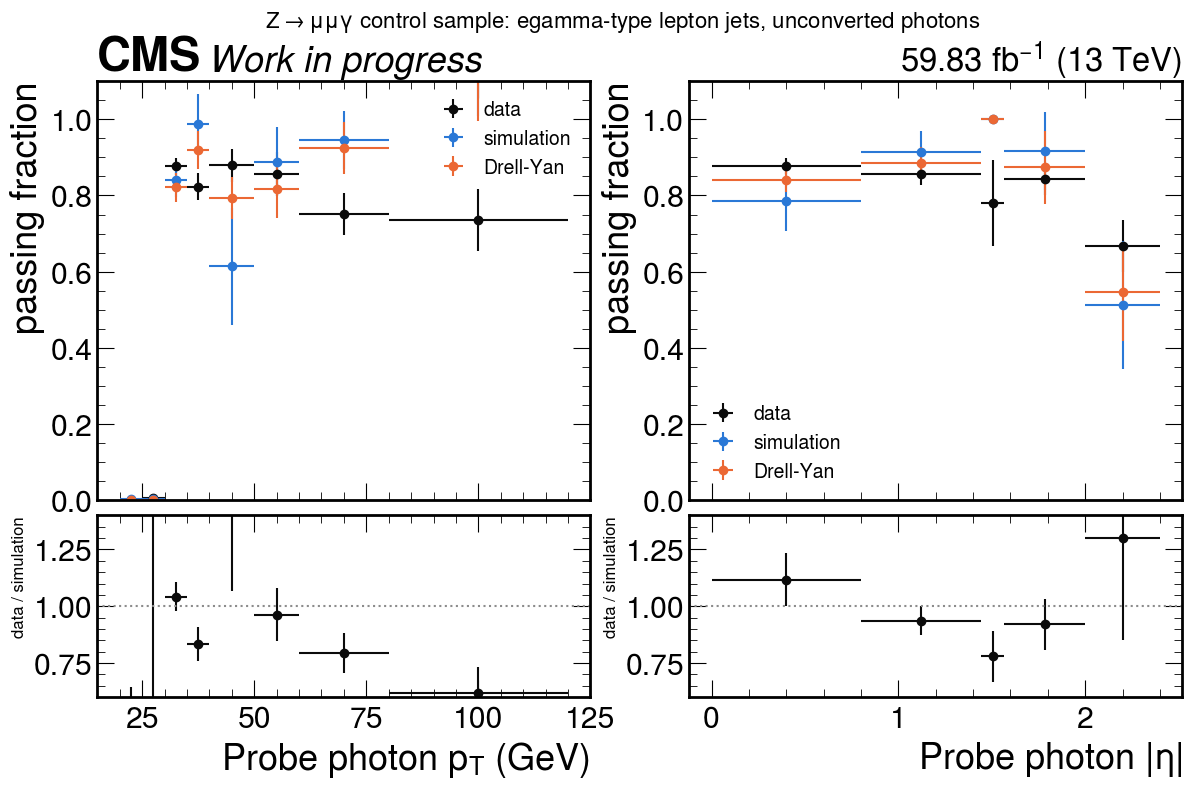

In [6]:
spec = sysstudy.LJ_CR["Z -> mumu gamma"]
dy = sum(sim["background"][s]["Z -> mumu gamma"] for s in sysstudy.LJ_CR_GROUPS[r"DY$\to\ell\ell$"]
         if s in sim["background"])
r9 = {"probe_r9": slice(hist.loc(0.94), None, sum)}
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05})
for col, axis in enumerate(("probe_pt", "probe_abseta")):
    sel = r9 if axis == "probe_pt" else Z_SELECTION
    results = {"data": sysstudy.probe_efficiency(data["Z -> mumu gamma"][sel], spec, axis),
               "simulation": sysstudy.probe_efficiency(sim_total["Z -> mumu gamma"][sel], spec, axis),
               "Drell-Yan": sysstudy.probe_efficiency(dy[sel], spec, axis)}
    sysstudy.plot_efficiency_comparison(results, "simulation", axes[0, col], axes[1, col])
    tables[("Z -> mumu gamma", axis)] = sysstudy.efficiency_table(results, "simulation")
    print(f"Z -> mumu gamma (R9 >= 0.94{'' if axis == 'probe_pt' else ', pT > 30 GeV'}) against {axis}:  data | simulation | data/simulation")
    for lo, hi, d, de, s, se, r, re in tables[("Z -> mumu gamma", axis)]:
        print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
# unconverted photons in wider ranges of pT
for name, pt_range in (("above 30 GeV", slice(hist.loc(30), None, sum)), ("30 to 60 GeV", slice(hist.loc(30), hist.loc(60), sum)),
                       ("above 60 GeV", slice(hist.loc(60), None, sum))):
    sel = {"probe_pt": pt_range, **r9}
    values = {label: sysstudy.integrated_efficiency(h[sel], spec) for label, h in
              (("data", data["Z -> mumu gamma"]), ("simulation", sim_total["Z -> mumu gamma"]), ("Drell-Yan", dy))}
    print(f"   unconverted photons {name}: " + ", ".join(f"{k} {e:.3f} +- {u:.3f} ({n:.0f} probes)" for k, (e, u, n) in values.items())
          + f"; data/Drell-Yan {values['data'][0] / values['Drell-Yan'][0]:.3f}")
fig.suptitle(f"{spec['label']} control sample: {spec['lj_type']} lepton jets, unconverted photons", fontsize=16, y=0.97)
pt.cms_label(axes[0], data=True, text="Work in progress")
save(fig, "efficiency_zmmg_data_simulation")
plt.show()

**Interpretation.** For unconverted photons above 30 GeV the passing fraction is 0.854 ± 0.016
in data, 0.842 ± 0.025 in Drell-Yan and 0.820 ± 0.052 in the whole simulation: data/Drell-Yan
**1.01 ± 0.04**, limited by the statistics of the simulation. From 30 to 60 GeV, which holds 90% of
the probes, the ratio is 1.04 ± 0.04; above 60 GeV the data pass in 0.756 ± 0.045 of the cases
against 0.942 ± 0.072 in Drell-Yan (0.80 ± 0.08, a difference of 2.2 standard deviations, from 112
probes in data). Against $|\eta|$ the passing fraction is lowest for $2.0 < |\eta| < 2.4$ in data
and simulation alike.

## 5. What the comparison gives

Written for the run of 2026-11-17 (`lj_reco_cr_data_v1`, `lj_reco_cr_v2`).

1. **Muon-type lepton jets, prompt and collimated.** Above 50 GeV, for opening angles from 0.03 to
   0.12, the simulation describes the passing fraction to about one percent: data/simulation
   0.988 ± 0.006 (0.976 ± 0.008 in the endcaps). This is the regime of the prompt muon-type lepton
   jets of the 5 GeV dark photons, and in part of the 1.2 GeV ones; the lepton jets of the signal
   are mostly above 50 GeV.
2. **Egamma-type lepton jets from unconverted photons.** Above 30 GeV, data/simulation 1.01 ±
   0.04, limited by the statistics of the simulation. Above 60 GeV the data are 0.80 ± 0.08 of the
   simulation, from 112 probes; more probes, or the purer selection that the converted photons
   need anyway, would tell whether this is a trend.
3. **Not measured by these samples:** the displaced DSA muons and the prompt electron pairs
   (question 5 of `lj_reco_efficiency.md`), the converted photons (a purer probe), and the most
   collimated muon pairs (below $\Delta R$ = 0.02 both samples hold few probes; question 4).
4. **For step 3.** The ratios above can become per-lepton-jet scale factors for the prompt regime;
   the granularity (per lepton jet or per constituent) and the treatment of the regimes not
   measured are the group's questions 2 to 5.

The figures and the passing fractions go to EOS, and the local working directory is removed.

In [7]:
with open(WORK / "passing_fractions.json", "w") as f:
    json.dump({f"{cr} | {axis}": [dict(zip(("low", "high", "data", "data_err", "simulation", "simulation_err",
                                            "ratio", "ratio_err"), map(float, row))) for row in table]
               for (cr, axis), table in tables.items()}, f, indent=1)
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_data_v1_results


## 6. Version 3: converted photons, and the displacement of the $J/\psi$ vertex

Campaign `lj_reco_cr_data_v2`: the same data files, with the histograms of version 3 of the two
control samples (`lj_reco_control_samples_v3`): the $Z \to \mu\mu\gamma$ probes with the selection
of final-state radiation (both muons isolated, $m(\mu\mu) + m(\mu\mu\gamma) < 180$ GeV), a purer
sample for the converted photons ($R_9 < 0.94$), and the $J/\psi$ probes against the displacement
$L_{xy}$ of their fitted dimuon vertex. The data are read through the safety table of version 3
(notebook 07, section 6.5), which `lj_cr_data` checks as in section 1; the simulation is campaign
`lj_reco_cr_v3`. The regions the table does not mark readable (the $J/\psi$ vertex bin above 15 cm)
are set to zero in the simulation as well, so that both cover the same regions.

In [8]:
DATA_DIR_V3 = sysstudy.eos_url(sysstudy.LJ_CR_DATA_V2_DIR)              # merged outputs of lj_reco_cr_data_v2
SIM_DIR_V3 = sysstudy.eos_url(sysstudy.LJ_CR_V3_DIR)                    # merged outputs of lj_reco_cr_v3
OUTPUT_DIR_V3 = sysstudy.eos_url(sysstudy.LJ_CR_DATA_V2_RESULTS_DIR)    # figures and passing fractions
if not sysstudy.list_coffea(DATA_DIR_V3):
    raise FileNotFoundError(f"No merged outputs in {DATA_DIR_V3} yet: run the campaign lj_reco_cr_data_v2 "
                            "(condor/README.md, section 23)")
WORK_V3 = Path(tempfile.mkdtemp(prefix="lj_reco_cr_data_v2_"))   # removed at the end
FSR, VTX = "Z -> mumu gamma, FSR", "J/psi -> mumu, vertex"


def save_v3(fig, name):
    """Write a figure of this section into its working directory, for EOS, as PDF and PNG"""
    for suffix in (".pdf", ".png"):
        fig.savefig(WORK_V3 / f"{name}{suffix}", bbox_inches="tight")


rows_v3 = sysstudy.lj_cr_verdicts(sysstudy.LJ_CR_V3_RESULTS_DIR)
for cr in sysstudy.LJ_CR_V3:
    print(f"{cr}: readable regions: {sysstudy.lj_cr_readable(rows_v3, cr)}")
data_v3 = sysstudy.lj_cr_data(rows_v3, DATA_DIR_V3, specs=sysstudy.LJ_CR_V3)
sim_v3 = sysstudy.lj_cr_inputs(SIM_DIR_V3, specs=sysstudy.LJ_CR_V3)
for per in sim_v3["background"].values():   # the regions the data step reads, in the simulation too
    for cr, spec in sysstudy.LJ_CR_V3.items():
        sysstudy.zero_unreadable(per[cr], rows_v3, cr, spec.get("split", "probe_pt"))
sim_v3_total = {cr: sum(per[cr] for per in sim_v3["background"].values()) for cr in sysstudy.LJ_CR_V3}
dy_v3 = sum(sim_v3["background"][s][FSR] for s in sysstudy.LJ_CR_GROUPS[r"DY$\to\ell\ell$"]
            if s in sim_v3["background"])
print()
for cr, spec in sysstudy.LJ_CR_V3.items():
    (lo, hi), sidebands = spec["peak"], spec["sidebands"]
    k = (hi - lo) / sum(b - a for a, b in sidebands)
    for label, h in (("data", data_v3[cr]), ("simulation", sim_v3_total[cr])):
        peak = sysstudy.mass_window(h, spec["mass"], lo, hi).sum(flow=True).value
        side = sum(sysstudy.mass_window(h, spec["mass"], a, b).sum(flow=True).value for a, b in sidebands)
        print(f"{cr:22s} {label:10s}: {peak:10.4g} probes in the peak, {peak - k * side:10.4g} after the subtraction")

Z -> mumu gamma, FSR: readable regions: ['probe_pt < 20', 'probe_pt 20 to 25', 'probe_pt 25 to 30', 'probe_pt 30 to 35', 'probe_pt 35 to 40', 'probe_pt 40 to 50', 'probe_pt 50 to 60', 'probe_pt 60 to 80', 'probe_pt 80 to 120', 'probe_pt >= 120']
J/psi -> mumu, vertex: readable regions: ['vtx_lxy < 0', 'vtx_lxy 0 to 0.01', 'vtx_lxy 0.01 to 0.02', 'vtx_lxy 0.02 to 0.05', 'vtx_lxy 0.05 to 0.1', 'vtx_lxy 0.1 to 0.2', 'vtx_lxy 0.2 to 0.5', 'vtx_lxy 0.5 to 1', 'vtx_lxy 1 to 2', 'vtx_lxy 2 to 5', 'vtx_lxy 5 to 15']



Z -> mumu gamma, FSR   data      :  1.389e+04 probes in the peak,       9983 after the subtraction
Z -> mumu gamma, FSR   simulation:  1.249e+04 probes in the peak,       9521 after the subtraction
J/psi -> mumu, vertex  data      :  3.997e+05 probes in the peak,   3.26e+05 after the subtraction
J/psi -> mumu, vertex  simulation:  4.762e+05 probes in the peak,  3.811e+05 after the subtraction


**Interpretation (run of 2026-11-24: `lj_reco_cr_data_v2`, all 68 data samples; simulation
`lj_reco_cr_v3`).** The safety table marks every region of the FSR sample readable, and every
$J/\psi$ vertex bin except the one above 15 cm, which is zero in data and simulation alike. After
the sideband subtraction the data hold 9,983 $Z \to \mu\mu\gamma$ probes of the FSR selection
against 9,521 in the simulation (a ratio of 1.05), and 326,000 $J/\psi$ probes against 381,000
(0.86, as in section 1). The passing fractions do not depend on these normalisations.

### 6.1 The probe mass

The FSR selection above 30 GeV, converted ($R_9 < 0.94$) and unconverted photons, passing and
failing together; the $J/\psi$ probes with a valid vertex. The simulation at its luminosity,
stacked by process; the data as points.

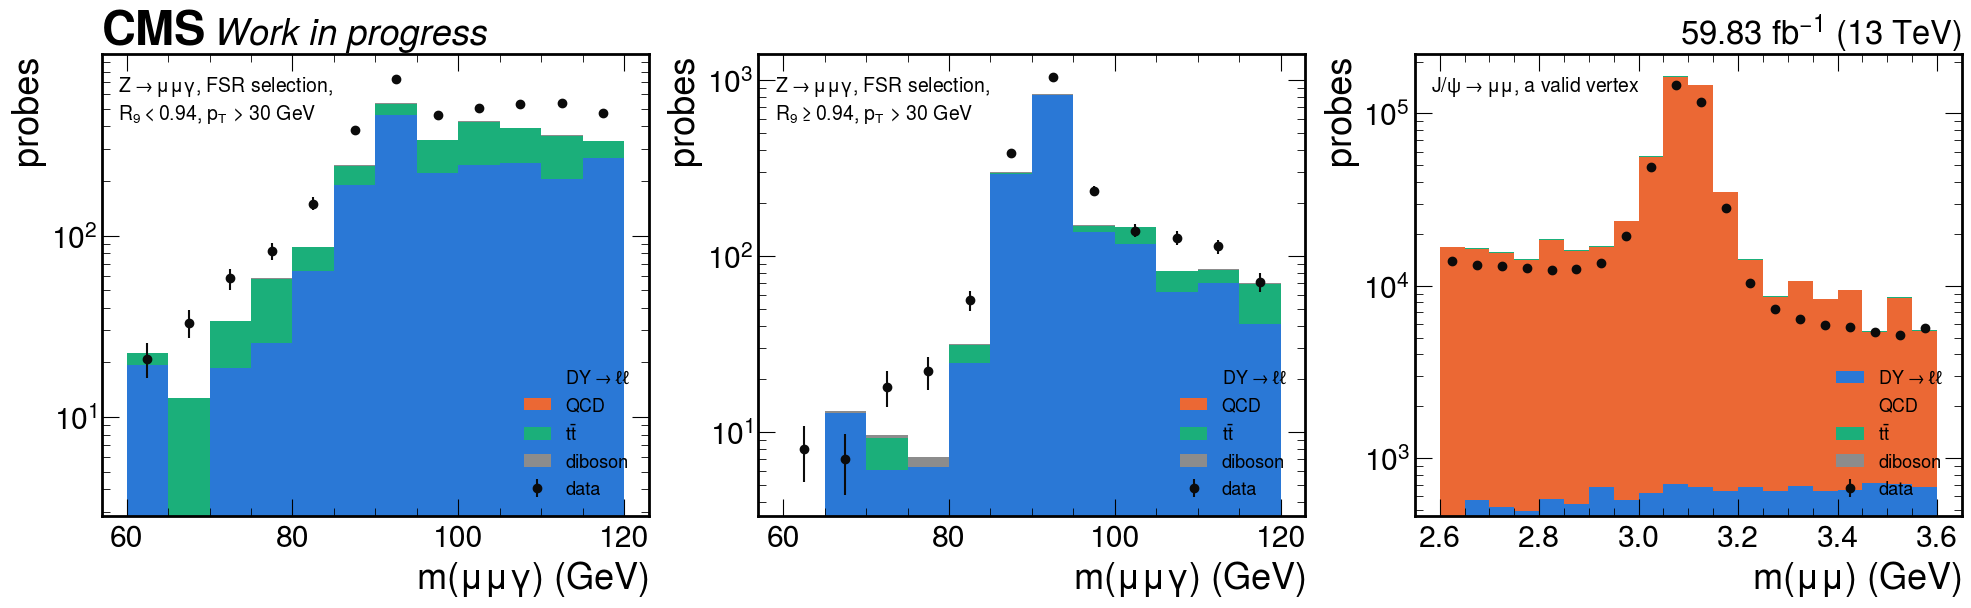

In [9]:
above30 = {"probe_pt": slice(hist.loc(30), None, sum)}
converted = {**above30, "probe_r9": slice(None, hist.loc(0.94), sum)}
unconverted = {**above30, "probe_r9": slice(hist.loc(0.94), None, sum)}
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
for ax, sel, name in ((axes[0], converted, r"$R_9 < 0.94$"), (axes[1], unconverted, r"$R_9 \geq 0.94$")):
    sysstudy.plot_mass_data_mc(data_v3, sim_v3, FSR, sel=sel, ax=ax, specs=sysstudy.LJ_CR_V3)
    ax.text(0.03, 0.86, sysstudy.LJ_CR_V3[FSR]["label"] + ",\n" + name + r", $p_T$ > 30 GeV",
            transform=ax.transAxes, fontsize=14)
sysstudy.plot_mass_data_mc(data_v3, sim_v3, VTX, sel={"vtx_lxy": slice(0, None, sum)}, ax=axes[2],
                           specs=sysstudy.LJ_CR_V3)
axes[2].text(0.03, 0.92, r"$J/\psi \to \mu\mu$, a valid vertex", transform=axes[2].transAxes, fontsize=14)
for ax in axes:
    ax.set_yscale("log")
    ax.legend(fontsize=13, loc="lower right")
pt.cms_label(axes, data=True, text="Work in progress")
save_v3(fig, "mass_data_simulation_v3")
plt.show()

**Interpretation.** With the FSR selection the $Z$ peak stands out for both kinds of photon, and
the simulation under it is Drell-Yan with a little $t\bar{t}$; no QCD probe is left. Above 30 GeV
the data hold 1.4 times as many converted and 1.25 times as many unconverted photons in the peak
as the simulation, with a similar excess in the sidebands: the subtraction removes about half of
the converted photons in the peak, 0.54 in data and 0.58 in the simulation, and 0.16 against 0.15
of the unconverted ones. The background under the peak is therefore as large a part of the data
as of the simulation, in which the closure of the subtraction was tested. The $J/\psi$ probes
with a valid vertex show the peak on a flat background of section 2, the data 14% below the
simulation.

### 6.2 Egamma-type lepton jets: converted photons

The passing fraction of the FSR selection in data, in the simulated background and in Drell-Yan
alone: against $R_9$ above 30 GeV, and against $p_T$ for converted and for unconverted photons.

Z -> mumu gamma, FSR, $p_T$ > 30 GeV, against probe_r9:  data | simulation | data/simulation
   0-0.5: 1.019 +- 0.478 | 1.203 +- 1.336 | 0.847 +- 1.021
   0.5-0.8: 0.883 +- 0.069 | 1.163 +- 0.283 | 0.759 +- 0.194
   0.8-0.9: 0.970 +- 0.074 | 1.061 +- 0.205 | 0.914 +- 0.190
   0.9-0.94: 0.841 +- 0.080 | 0.926 +- 0.144 | 0.909 +- 0.166
   0.94-1: 0.836 +- 0.015 | 0.839 +- 0.028 | 0.997 +- 0.037
Z -> mumu gamma, FSR, $R_9 < 0.94$, against probe_pt:  data | simulation | data/simulation
   20-25: 0.004 +- 0.002 | 0.002 +- 0.003 | 1.750 +- 2.667
   25-30: 0.014 +- 0.006 | -0.001 +- 0.005 | -10.394 +- 41.460
   30-35: 0.862 +- 0.064 | 0.904 +- 0.136 | 0.953 +- 0.160
   35-40: 0.797 +- 0.081 | 1.098 +- 0.306 | 0.726 +- 0.216
   40-50: 1.079 +- 0.158 | 2.559 +- 2.357 | 0.422 +- 0.393
   50-60: 1.579 +- 0.568 | 0.692 +- 0.283 | 2.280 +- 1.241
   60-80: 0.822 +- 0.197 | 0.991 +- 0.711 | 0.830 +- 0.628
   80-120: 1.250 +- 0.542 | 7.585 +- 36.495 | 0.165 +- 0.796
Z -> mumu gamma, FSR, $R_9 \geq 0.9

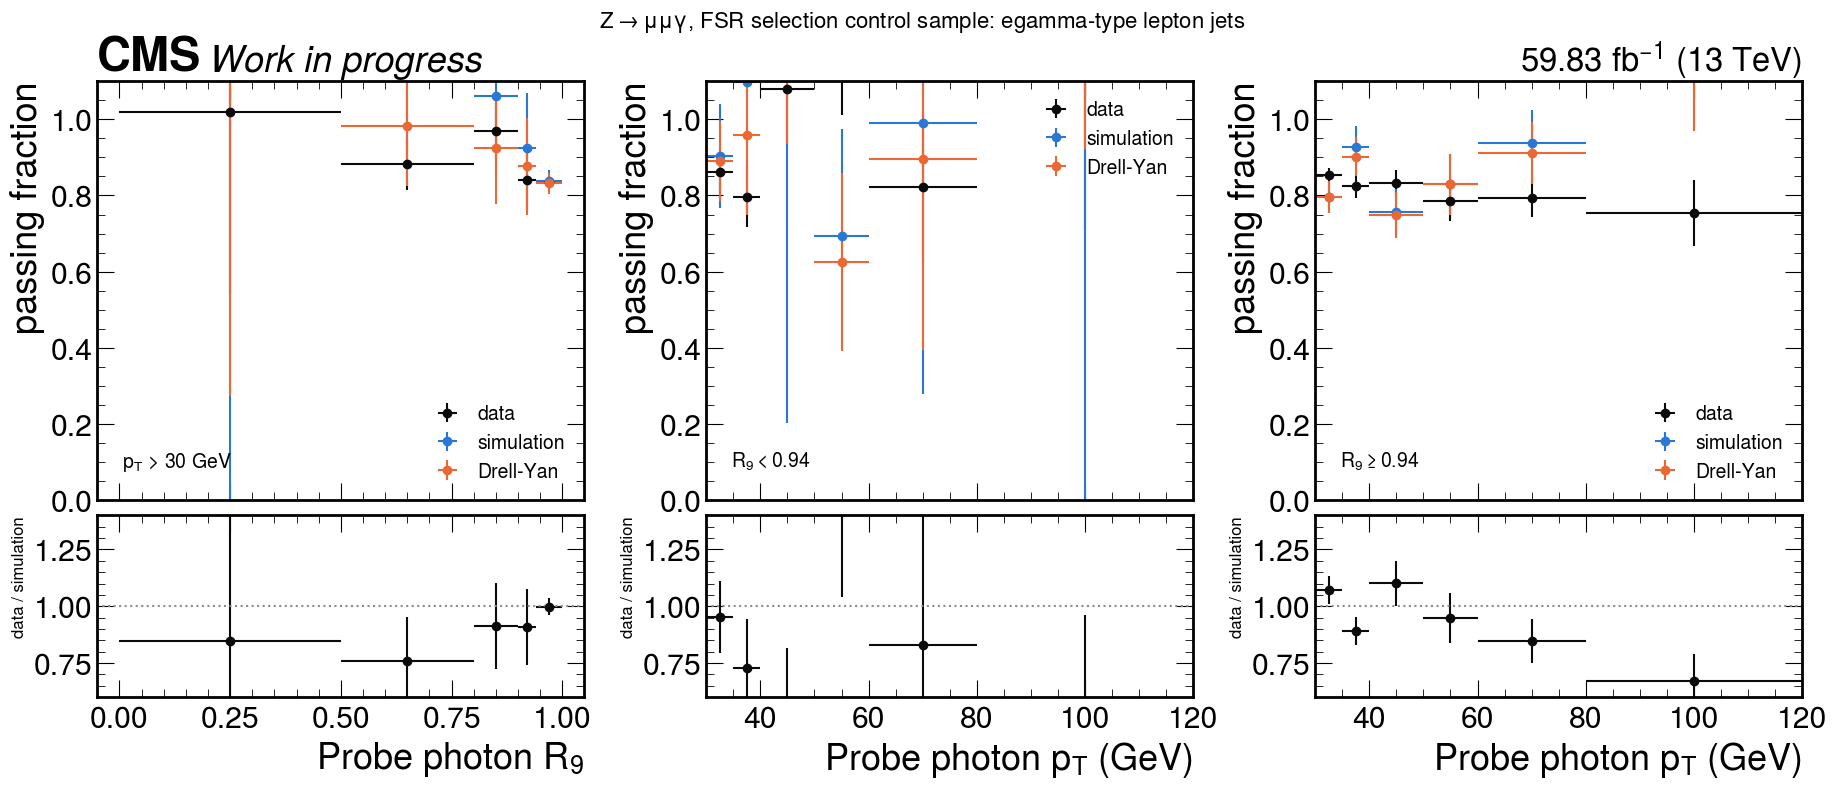

converted photons above 30 GeV: data 0.908 +- 0.048 (512 probes), simulation 1.079 +- 0.143 (326 probes), Drell-Yan 0.966 +- 0.094 (371 probes); data/Drell-Yan 0.940 +- 0.104
converted photons, 30 to 60 GeV: data 0.907 +- 0.049 (482 probes), simulation 1.047 +- 0.138 (311 probes), Drell-Yan 0.956 +- 0.095 (349 probes); data/Drell-Yan 0.949 +- 0.108
converted photons above 60 GeV: data 0.934 +- 0.197 (30 probes), simulation 1.754 +- 1.595 (15 probes), Drell-Yan 1.131 +- 0.518 (22 probes); data/Drell-Yan 0.826 +- 0.416
unconverted photons above 30 GeV: data 0.834 +- 0.013 (1194 probes), simulation 0.824 +- 0.027 (965 probes), Drell-Yan 0.816 +- 0.026 (970 probes); data/Drell-Yan 1.021 +- 0.037


In [10]:
spec_f = sysstudy.LJ_CR_V3[FSR]
tables_v3 = {}
fig, axes = plt.subplots(2, 3, figsize=(22, 8), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05, "wspace": 0.25})
panels = ((0, "probe_r9", above30, r"$p_T$ > 30 GeV"),
          (1, "probe_pt", {"probe_r9": slice(None, hist.loc(0.94), sum)}, r"$R_9 < 0.94$"),
          (2, "probe_pt", {"probe_r9": slice(hist.loc(0.94), None, sum)}, r"$R_9 \geq 0.94$"))
for col, axis, sel, name in panels:
    results = {"data": sysstudy.probe_efficiency(data_v3[FSR][sel], spec_f, axis),
               "simulation": sysstudy.probe_efficiency(sim_v3_total[FSR][sel], spec_f, axis),
               "Drell-Yan": sysstudy.probe_efficiency(dy_v3[sel], spec_f, axis)}
    sysstudy.plot_efficiency_comparison(results, "simulation", axes[0, col], axes[1, col])
    axes[0, col].text(0.05, 0.08, name, transform=axes[0, col].transAxes, fontsize=14)
    tables_v3[(FSR, axis, name)] = sysstudy.efficiency_table(results, "simulation")
    print(f"{FSR}, {name}, against {axis}:  data | simulation | data/simulation")
    for lo, hi, d, de, s, se, r, re in tables_v3[(FSR, axis, name)]:
        print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
for col in (1, 2):
    axes[1, col].set_xlim(30, 120)   # below 30 GeV no probe passes: the lepton-jet threshold
fig.suptitle(f"{spec_f['label']} control sample: {spec_f['lj_type']} lepton jets", fontsize=16, y=0.97)
pt.cms_label(axes[0], data=True, text="Work in progress")
save_v3(fig, "efficiency_zmmg_fsr_data_simulation")
plt.show()
for name, sel in (("converted photons above 30 GeV", converted),
                  ("converted photons, 30 to 60 GeV", {**converted, "probe_pt": slice(hist.loc(30), hist.loc(60), sum)}),
                  ("converted photons above 60 GeV", {**converted, "probe_pt": slice(hist.loc(60), None, sum)}),
                  ("unconverted photons above 30 GeV", unconverted)):
    values = {label: sysstudy.integrated_efficiency(h[sel], spec_f) for label, h in
              (("data", data_v3[FSR]), ("simulation", sim_v3_total[FSR]), ("Drell-Yan", dy_v3))}
    (d, de, _), (y, ye, _) = values["data"], values["Drell-Yan"]
    print(f"{name}: " + ", ".join(f"{k} {e:.3f} +- {u:.3f} ({n:.0f} probes)" for k, (e, u, n) in values.items())
          + f"; data/Drell-Yan {d / y:.3f} +- {d / y * np.hypot(de / d, ye / y):.3f}")

**Interpretation.** *Unconverted photons* ($R_9 \geq 0.94$) above 30 GeV pass in 0.834 ± 0.013
of the cases in data and 0.816 ± 0.026 in Drell-Yan, a ratio of 1.02 ± 0.04: 1.04 ± 0.04 from 30
to 60 GeV, which holds 92% of the probes, and 0.86 ± 0.09 above 60 GeV (100 probes, 1.5 standard
deviations below one). In data the passing fraction falls slowly with $p_T$, from 0.85 to 0.75;
the simulation scatters by more than that (0.76 to 1.12), so whether it shares the trend cannot
be seen.

*Converted photons* ($R_9 < 0.94$) above 30 GeV pass in 0.908 ± 0.048 of the cases in data (512
probes after the subtraction) and 0.966 ± 0.094 in Drell-Yan (371), a ratio of 0.94 ± 0.10; 0.95 ±
0.11 from 30 to 60 GeV, and only 30 data probes above. Against $R_9$ the ratio is 0.76 ± 0.19,
0.91 ± 0.19 and 0.91 ± 0.17 in the three bins from 0.5 to 0.94, each within 1.3 standard
deviations of one. The simulation sets the precision: it holds fewer probes than the data, with
larger weights, and with every background its passing fraction is above one in three of the six
$p_T$ bins from 30 GeV (1.08 ± 0.14 in total), which the subtraction gives when the simulated
background fluctuates. The closure test of notebook 07 (section 6.1) agrees for these photons
within the uncertainties of the simulation, so the comparison is good to its own statistical
uncertainty, about 10%.

### 6.3 Muon-type lepton jets against the displacement of the $J/\psi$ vertex

Above 50 GeV, the passing fraction in data and in the simulated background against the vertex
$L_{xy}$, and the distribution of the probes over $L_{xy}$ after the sideband subtraction (the
first bin: no valid vertex; the last, above 15 cm, is not read), each normalised to one. The data hold prompt $J/\psi$ as well as
those from b-hadron decays; the simulation (QCD) almost only the latter.

J/psi -> mumu, vertex, pT > 50 GeV, against vtx_lxy:  data | simulation | data/simulation
   0-0.01: 0.985 +- 0.001 | 1.006 +- 0.016 | 0.979 +- 0.015
   0.01-0.02: 0.984 +- 0.001 | 1.006 +- 0.004 | 0.978 +- 0.004
   0.02-0.05: 0.984 +- 0.001 | 1.113 +- 0.143 | 0.884 +- 0.114
   0.05-0.1: 0.983 +- 0.001 | 0.987 +- 0.010 | 0.996 +- 0.011
   0.1-0.2: 0.979 +- 0.001 | 0.981 +- 0.008 | 0.998 +- 0.009
   0.2-0.5: 0.979 +- 0.001 | 0.983 +- 0.006 | 0.995 +- 0.007
   0.5-1: 0.980 +- 0.001 | 0.985 +- 0.007 | 0.995 +- 0.007
   1-2: 0.981 +- 0.001 | 0.987 +- 0.005 | 0.995 +- 0.005
   2-5: 0.985 +- 0.002 | 0.995 +- 0.005 | 0.989 +- 0.005
   5-15: 0.979 +- 0.017 | 0.964 +- 0.114 | 1.015 +- 0.121


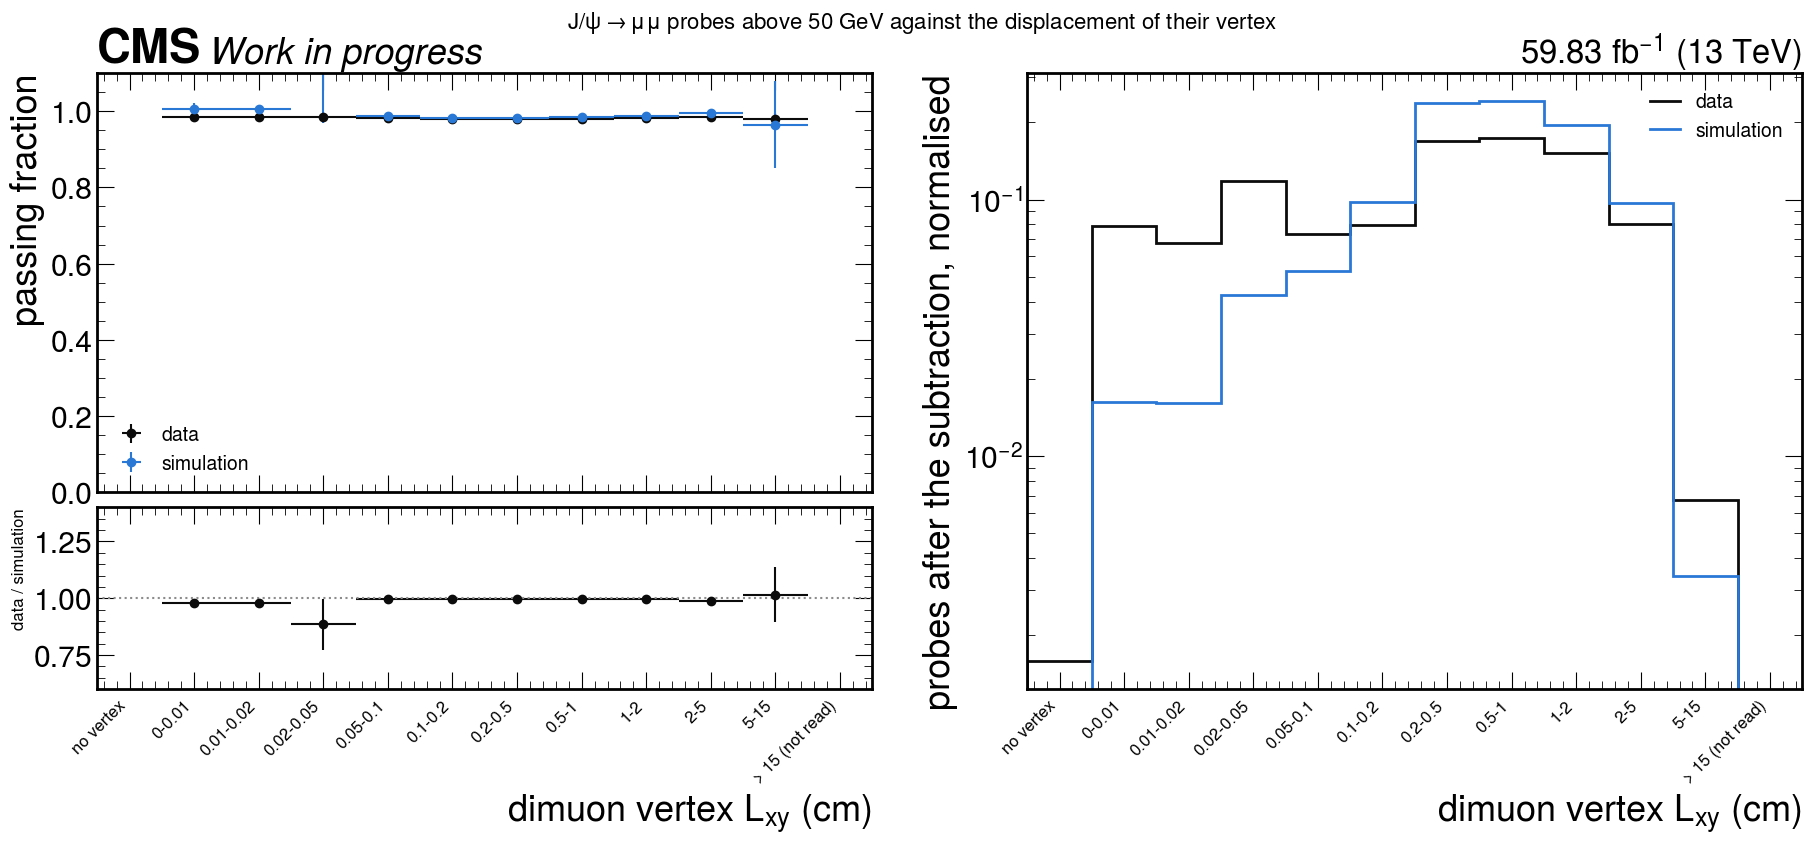

no valid vertex: data 1.0124 +- 0.0967 (484 probes), simulation -0.7366 +- -2.0708 (-304 probes); data/simulation -1.374 +- -3.866
L_xy < 0.01 cm: data 0.9852 +- 0.0011 (24131 probes), simulation 1.0064 +- 0.0158 (5740 probes); data/simulation 0.979 +- 0.015
L_xy 0.01 to 0.1 cm: data 0.9838 +- 0.0006 (79202 probes), simulation 1.0381 +- 0.0511 (39354 probes); data/simulation 0.948 +- 0.047
L_xy above 0.1 cm, readable bins: data 0.9805 +- 0.0005 (201451 probes), simulation 0.9855 +- 0.0031 (308813 probes); data/simulation 0.995 +- 0.003


In [11]:
spec_v = sysstudy.LJ_CR_V3[VTX]
above50 = {"probe_pt": slice(hist.loc(50), None, sum)}
results = {"data": sysstudy.probe_efficiency(data_v3[VTX][above50], spec_v, "vtx_lxy"),
           "simulation": sysstudy.probe_efficiency(sim_v3_total[VTX][above50], spec_v, "vtx_lxy")}
tables_v3[(VTX, "vtx_lxy", "pT > 50 GeV")] = sysstudy.efficiency_table(results, "simulation")
print(f"{VTX}, pT > 50 GeV, against vtx_lxy:  data | simulation | data/simulation")
for lo, hi, d, de, s, se, r, re in tables_v3[(VTX, "vtx_lxy", "pT > 50 GeV")]:
    print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
edges = results["data"]["edges"]
n = len(edges) - 1
bounds = np.arange(-1, n + 2)
labels = (["no vertex"] + [f"{lo:g}-{hi:g}" for lo, hi in zip(edges[:-1], edges[1:])] + [f"> {edges[-1]:g}"])
keep = sysstudy.readable_bins(rows_v3, VTX, data_v3[VTX].axes["vtx_lxy"])
labels = [lab if i in keep else f"{lab} (not read)" for i, lab in enumerate(labels)]
fig = plt.figure(figsize=(22, 8))
grid = fig.add_gridspec(2, 2, height_ratios=[3, 1.3], hspace=0.05, wspace=0.2)
top, bottom = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, 0])
sysstudy.plot_efficiency_comparison(results, "simulation", top, bottom, categorical=True)
top.sharex(bottom)
right = fig.add_subplot(grid[:, 1])
for label, colour in (("data", study.BLACK), ("simulation", study.BLUE)):
    probes = results[label]["probes"]
    right.stairs(probes / probes.sum(), bounds, color=colour, linewidth=2, label=label)
right.set_yscale("log")
right.set_ylabel("probes after the subtraction, normalised")
right.legend(fontsize=14)
for ax in (bottom, right):
    ax.set_xlim(-1, n + 1)
    ax.set_xticks(bounds[:-1] + 0.5, labels, rotation=45, ha="right", fontsize=12)
    ax.set_xlabel(r"dimuon vertex $L_{xy}$ (cm)")
top.set_xlim(-1, n + 1)
fig.suptitle(r"$J/\psi \to \mu\mu$ probes above 50 GeV against the displacement of their vertex", fontsize=16, y=0.96)
pt.cms_label([top, right], data=True, text="Work in progress")
save_v3(fig, "efficiency_jpsi_vertex_data_simulation")
plt.show()
for name, sl in (("no valid vertex", slice(None, 0, sum)), ("L_xy < 0.01 cm", slice(0, hist.loc(0.01), sum)),
                 ("L_xy 0.01 to 0.1 cm", slice(hist.loc(0.01), hist.loc(0.1), sum)),
                 ("L_xy above 0.1 cm, readable bins", slice(hist.loc(0.1), None, sum))):
    values = {label: sysstudy.integrated_efficiency(h[{**above50, "vtx_lxy": sl}], spec_v)
              for label, h in (("data", data_v3[VTX]), ("simulation", sim_v3_total[VTX]))}
    (d, de, _), (s, se, _) = values["data"], values["simulation"]
    print(f"{name}: " + ", ".join(f"{k} {e:.4f} +- {u:.4f} ({m:.0f} probes)" for k, (e, u, m) in values.items())
          + f"; data/simulation {d / s:.3f} +- {d / s * np.hypot(de / d, se / s):.3f}")

**Interpretation.** Above 50 GeV the passing fraction in data is flat in the displacement of the
vertex: 0.979 to 0.985 in every bin from 0 to 15 cm, and 1.01 ± 0.10 for the 484 probes without a
valid vertex. The simulation is flat too from 0.5 mm on (0.981 to 0.995 out to 5 cm, 0.96 ± 0.11
from 5 to 15 cm); there the ratio is 0.989 to 0.998 in each bin out to 5 cm and 1.02 ± 0.12 from 5
to 15 cm, and 0.995 ± 0.003 for all $L_{xy}$ above 1 mm. The simulated $J/\psi$ come almost only
from b-hadron decays: 1.6% of its probes lie within 0.1 mm of the beam line, against 7.9% of those
in data. Below 0.5 mm its subtraction gives passing fractions at or above one (1.006 ± 0.004 from
0.1 to 0.2 mm, 1.11 ± 0.14 from 0.2 to 0.5 mm), which no true efficiency can have, hence ratios of
0.98 and 0.88 ± 0.11 there. The data, whose prompt $J/\psi$ lie at these small displacements, show
no change of the passing fraction there. The simulation has no probes without a valid vertex (the
subtraction leaves a negative count).

### 6.4 What version 3 gives

- **Muon-type, against the displacement.** The passing fraction of the $J/\psi$ probes above 50
  GeV does not depend on the displacement of their vertex out to 15 cm, in data (0.979 to 0.985)
  or in the simulation (from 0.5 mm on). For $L_{xy}$ above 1 mm, where the simulation is precise,
  data/simulation is 0.995 ± 0.003. The integrated ratio of section 3, 0.988 ± 0.006, also takes in
  the vertices below 0.5 mm, where the simulated passing fraction comes out at or above one.
- **Egamma-type, converted photons.** Measured for the first time: data/Drell-Yan 0.94 ± 0.10
  above 30 GeV, consistent with one; the simulated statistics set its precision, and the closure
  test of notebook 07 agrees for these photons within the same uncertainties.
- **Egamma-type, unconverted photons.** With the FSR selection data/Drell-Yan is 1.02 ± 0.04 above
  30 GeV and 0.86 ± 0.09 above 60 GeV, in line with section 4 (1.01 ± 0.04 and 0.80 ± 0.08).
- **Not reached:** displaced DSA muons, prompt electron pairs, muon pairs below $\Delta R$ = 0.03,
  and converted photons above 60 GeV (30 probes in data). Step 3 takes the nearest measured bin
  for them, each case recorded.

In [12]:
with open(WORK_V3 / "passing_fractions.json", "w") as f:
    json.dump({" | ".join(key): [dict(zip(("low", "high", "data", "data_err", "simulation", "simulation_err",
                                         "ratio", "ratio_err"), map(float, row))) for row in table]
               for key, table in tables_v3.items()}, f, indent=1)
sysstudy.upload(WORK_V3, OUTPUT_DIR_V3)
shutil.rmtree(WORK_V3)
print("outputs in", OUTPUT_DIR_V3)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_data_v2_results
